# 04 - Model 1: MFCC -> Random Forest / SVM



In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

CLASS_NAMES = ["good", "broken", "heavyload"]

# load the MFCC features saved by 03_features
F_train = np.load("features/F_train.npy")
F_val = np.load("features/F_val.npy")
y_train = np.load("features/y_train.npy")
y_val = np.load("features/y_val.npy")
val_recordings = np.load("features/val_recordings.npy")

print("Train:", F_train.shape, "Val:", F_val.shape)

Train: (357, 13) Val: (442, 13)


## 1. Scale the features



In [2]:
scaler = StandardScaler()
F_train_scaled = scaler.fit_transform(F_train)   # learns mean and std from train
F_val_scaled = scaler.transform(F_val)           # uses the train mean and std

## 2. First try with default settings

In [3]:
svm = SVC(kernel="rbf")
svm.fit(F_train_scaled, y_train)
svm_pred = svm.predict(F_val_scaled)

rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(F_train, y_train)
rf_pred = rf.predict(F_val)

print("SVM val accuracy:", round(accuracy_score(y_val, svm_pred), 3))
print("RF  val accuracy:", round(accuracy_score(y_val, rf_pred), 3))

SVM val accuracy: 0.317
RF  val accuracy: 0.609


## 3. Tune the settings on validation


In [4]:
# SVM: try all combinations of C and gamma
best_svm_score = 0

for C in [0.1, 1, 10, 100]:
    for gamma in ["scale", 0.01, 0.1, 1]:
        model = SVC(kernel="rbf", C=C, gamma=gamma)
        model.fit(F_train_scaled, y_train)
        pred = model.predict(F_val_scaled)
        score = f1_score(y_val, pred, average="macro")
        print("SVM  C =", C, " gamma =", gamma, " val F1 =", round(score, 3))

        if score > best_svm_score:          # keep the best one
            best_svm_score = score
            best_svm = model
            best_svm_settings = {"C": C, "gamma": gamma}

print("Best SVM:", best_svm_settings, "val F1 =", round(best_svm_score, 3))

SVM  C = 0.1  gamma = scale  val F1 = 0.16
SVM  C = 0.1  gamma = 0.01  val F1 = 0.16
SVM  C = 0.1  gamma = 0.1  val F1 = 0.16
SVM  C = 0.1  gamma = 1  val F1 = 0.16
SVM  C = 1  gamma = scale  val F1 = 0.16
SVM  C = 1  gamma = 0.01  val F1 = 0.169
SVM  C = 1  gamma = 0.1  val F1 = 0.16
SVM  C = 1  gamma = 1  val F1 = 0.16
SVM  C = 10  gamma = scale  val F1 = 0.16
SVM  C = 10  gamma = 0.01  val F1 = 0.187
SVM  C = 10  gamma = 0.1  val F1 = 0.16
SVM  C = 10  gamma = 1  val F1 = 0.16
SVM  C = 100  gamma = scale  val F1 = 0.16
SVM  C = 100  gamma = 0.01  val F1 = 0.187
SVM  C = 100  gamma = 0.1  val F1 = 0.16
SVM  C = 100  gamma = 1  val F1 = 0.16
Best SVM: {'C': 10, 'gamma': 0.01} val F1 = 0.187


In [5]:
# Random Forest: try all combinations of max_depth and min_samples_leaf
best_rf_score = 0

for max_depth in [None, 5, 10]:
    for min_samples_leaf in [1, 3, 5]:
        model = RandomForestClassifier(n_estimators=300, max_depth=max_depth,
                                       min_samples_leaf=min_samples_leaf, random_state=42)
        model.fit(F_train, y_train)
        pred = model.predict(F_val)
        score = f1_score(y_val, pred, average="macro")
        print("RF  max_depth =", max_depth, " min_samples_leaf =", min_samples_leaf, " val F1 =", round(score, 3))

        if score > best_rf_score:
            best_rf_score = score
            best_rf = model
            best_rf_settings = {"max_depth": max_depth, "min_samples_leaf": min_samples_leaf}

print("Best RF:", best_rf_settings, "val F1 =", round(best_rf_score, 3))

RF  max_depth = None  min_samples_leaf = 1  val F1 = 0.55
RF  max_depth = None  min_samples_leaf = 3  val F1 = 0.55
RF  max_depth = None  min_samples_leaf = 5  val F1 = 0.52
RF  max_depth = 5  min_samples_leaf = 1  val F1 = 0.55
RF  max_depth = 5  min_samples_leaf = 3  val F1 = 0.55
RF  max_depth = 5  min_samples_leaf = 5  val F1 = 0.52
RF  max_depth = 10  min_samples_leaf = 1  val F1 = 0.55
RF  max_depth = 10  min_samples_leaf = 3  val F1 = 0.55
RF  max_depth = 10  min_samples_leaf = 5  val F1 = 0.52
Best RF: {'max_depth': None, 'min_samples_leaf': 1} val F1 = 0.55


## 4. Quick check of the best models on validation



In [6]:
svm_pred = best_svm.predict(F_val_scaled)
rf_pred = best_rf.predict(F_val)

for rec in ["talking_1", "atmo_medium"]:
    mask = val_recordings == rec
    print(rec)
    print("  SVM accuracy:", round(accuracy_score(y_val[mask], svm_pred[mask]), 3))
    print("  RF  accuracy:", round(accuracy_score(y_val[mask], rf_pred[mask]), 3))

talking_1
  SVM accuracy: 0.333
  RF  accuracy: 0.526
atmo_medium
  SVM accuracy: 0.327
  RF  accuracy: 0.696


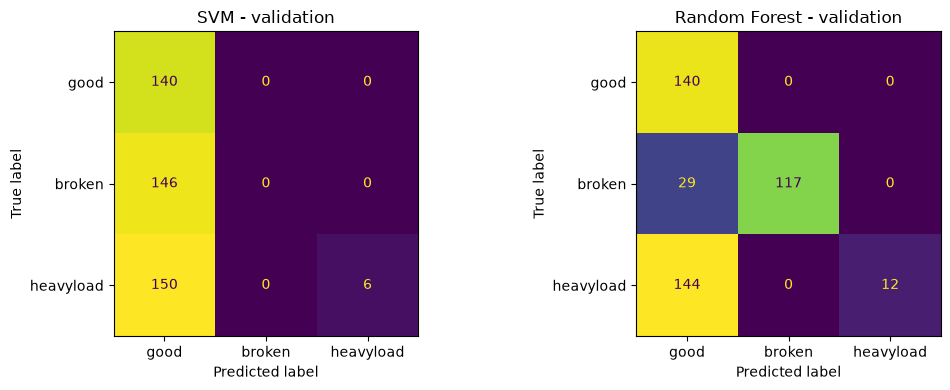

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(confusion_matrix(y_val, svm_pred), display_labels=CLASS_NAMES).plot(ax=axes[0], colorbar=False)
axes[0].set_title("SVM - validation")

ConfusionMatrixDisplay(confusion_matrix(y_val, rf_pred), display_labels=CLASS_NAMES).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Random Forest - validation")

plt.tight_layout()
plt.show()

### Which MFCCs does the Random Forest use most?


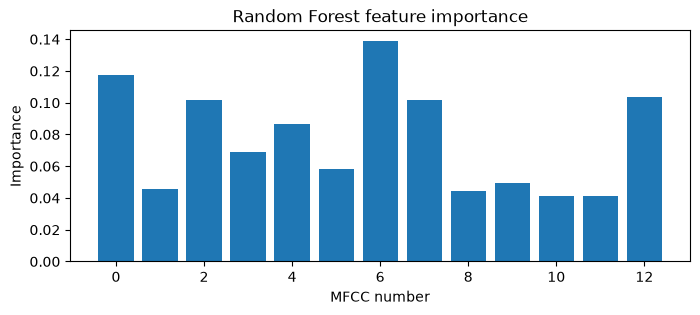

In [8]:
plt.figure(figsize=(8, 3))
plt.bar(range(len(best_rf.feature_importances_)), best_rf.feature_importances_)
plt.xlabel("MFCC number")
plt.ylabel("Importance")
plt.title("Random Forest feature importance")
plt.show()

## 5. Save the models for the evaluation notebook


In [9]:
os.makedirs("models", exist_ok=True)

joblib.dump(best_svm, "models/model1_svm.joblib")
joblib.dump(scaler, "models/model1_scaler.joblib")
joblib.dump(best_rf, "models/model1_rf.joblib")

print("Saved models to models/")

Saved models to models/
